# **Práctica 3: Tarea de clasificación**
### Introducción a la Ciencia de Datos
*Alumno: Norman O. Guzmán Chaboya*

En esta práctica se construye un clasificador que predice, al cierre del primer semestre, la situación que tendrá un estudiante al final de la duración normal de su carrera: graduado, desertor o todavía inscrito. Para ello se utilizan datos reales de 4,424 estudiantes de licenciatura del Instituto Politécnico de Portalegre, en Portugal, que ingresaron entre los ciclos 2008/09 y 2018/19. El conjunto de entrenamiento incluye a 3,539 estudiantes con sus 36 atributos y la variable objetivo, mientras que el de prueba contiene a 885 estudiantes sin la variable objetivo y únicamente con los atributos que se conocen al cierre del primer semestre.

Se comparan cinco clasificadores (árbol de decisión, Naive Bayes, k vecinos más cercanos, máquinas de soporte vectorial y regresión logística).

A lo largo del *notebook*, sea realiza lo siguiente:

1. Descripción del conjunto de datos.
2. Preprocesamiento por clasificador.
3. Optimización de hiperparámetros.
4. Comparación de los clasificadores.
5. Matriz de confusión y análisis de la clase desertor.
6. Estimación con datos del cierre del segundo semestre.
7. Clasificador final y predicciones.
8. Discusión y conclusiones

In [1]:
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('bmh')
import optuna

ran = 42
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.naive_bayes import BernoulliNB, ComplementNB, MultinomialNB
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import multilabel_confusion_matrix
from sklearn.dummy import DummyClassifier

import warnings

In [2]:
class display(object):
    # Función para observar simultáneamente múltiples objetos HTML
    template = """<div style="float: left; padding: 10px;">
    <p style='font-family:"Courier New", Courier, monospace'>{0}</p>{1}
    </div>"""
    def __init__(self, *args):
        self.args = args

    def _repr_html_(self):
        return '\n'.join(self.template.format(a, eval(a)._repr_html_())
                         for a in self.args)

    def __repr__(self):
        return '\n\n'.join(a + '\n' + repr(eval(a))
                           for a in self.args)

## 1. Conjunto de datos

El objetivo es construir un clasificador que prediga, al cierre del primer semestre, la situación que tendrá un estudiante al final de la duración normal de su carrera (tres años; cuatro en Enfermería): graduado (`graduate`), desertor (`dropout`) o todavía inscrito (`enrolled`). Un modelo así permitiría identificar a tiempo a los estudiantes en riesgo para ofrecerles apoyo.

Los datos son reales: 4,424 estudiantes de licenciatura del Instituto Politécnico de Portalegre que ingresaron entre los ciclos 2008/09 y 2018/19, recopilados en el [*UCI Machine Learning Repository*](https://archive.ics.uci.edu/dataset/697). La clase desertor incluye también los cambios de carrera o de institución, sin importar cuándo ocurrieron.

El repositorio del curso divide a los estudiantes en un conjunto de entrenamiento (con `Target`) y uno de prueba (sin `Target` ni los atributos del segundo semestre).

Importamos los respectivos conjuntos de prueba y entrenamiento:

In [3]:
entrena = pd.read_csv('data/desercion-entrenamiento.csv')
prueba = pd.read_csv('data/desercion-prueba.csv')
entrena['Target'] = entrena['Target'].str.lower()

print(f"Entrenamiento: {entrena.shape[0]} estudiantes, {entrena.shape[1]} columnas | Prueba: {prueba.shape[0]} estudiantes, {prueba.shape[1]} columnas")

Entrenamiento: 3539 estudiantes, 38 columnas | Prueba: 885 estudiantes, 31 columnas


### 1.1 Distribución de las clases

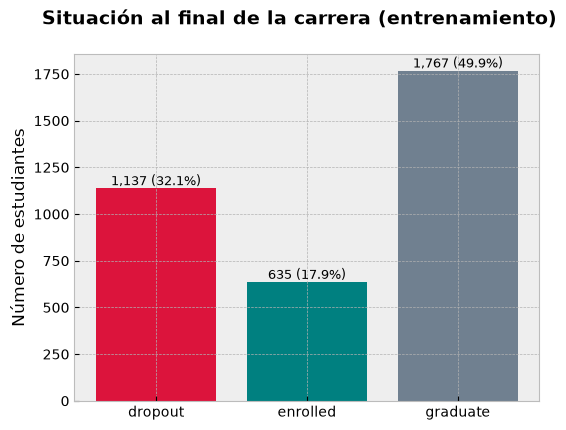

In [4]:
orden_clases = ['dropout', 'enrolled', 'graduate']
colores_cl = {'dropout': 'crimson', 'enrolled': 'teal', 'graduate': 'slategrey'}
conteo = entrena['Target'].value_counts().reindex(orden_clases)

with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.bar(conteo.index, conteo.values, color=[colores_cl[c] for c in conteo.index])
    for j, v in enumerate(conteo.values):
        ax.text(j, v + conteo.max()*0.01, f'{v:,} ({v/len(entrena)*100:.1f}%)', ha='center', fontsize=9)
    ax.set_ylabel('Número de estudiantes')
    fig.suptitle('Situación al final de la carrera (entrenamiento)', fontweight='bold', fontsize=14)
    plt.show()

Las clases están desbalanceadas: la mitad de los estudiantes se gradúa (49.9%), casi un tercio deserta (32.1%) y solo el 17.9% sigue inscrito, siendo esta última es la clase minoritaria

### 1.2. Atributos

In [5]:
cols_nominales = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
                  "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
cols_binarias = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
                 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
cols_ordinales = ['Application order']
cols_macro = ['Unemployment rate', 'Inflation rate', 'GDP']
cols_1s = [c for c in entrena.columns if '1st sem' in c]
cols_2s = [c for c in entrena.columns if '2nd sem' in c]
cols_numericas = ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment'] + cols_1s + cols_macro

In [6]:
# Atributos conocidos al cierre del primer semestre
atributos = cols_nominales + cols_binarias + cols_ordinales + cols_numericas

# Tipo de cada atributo
tipo = {**dict.fromkeys(cols_nominales, 'nominal'), **dict.fromkeys(cols_binarias, 'binario'),
        **dict.fromkeys(cols_ordinales, 'ordinal'), **dict.fromkeys(cols_numericas + cols_2s, 'numérico')}

todos = atributos + cols_2s
tipos_df = pd.DataFrame({'tipo': [tipo[c] for c in todos],
                         'valores distintos': [entrena[c].nunique() for c in todos],
                         'rango': [f'{entrena[c].min():g} a {entrena[c].max():g}' for c in todos]},
                        index=todos)
resumen_tipos = tipos_df['tipo'].value_counts().to_frame('atributos')

display('tipos_df', 'resumen_tipos')

,tipo,valores distintos,rango
Marital status,nominal,6,1 a 6
Application mode,nominal,17,1 a 57
Course,nominal,17,33 a 9991
Previous qualification,nominal,17,1 a 43
Nacionality,nominal,18,1 a 109
Mother's qualification,nominal,26,1 a 44
Father's qualification,nominal,32,1 a 44
Mother's occupation,nominal,31,0 a 194
Father's occupation,nominal,45,0 a 195
Daytime/evening attendance,binario,2,0 a 1


De los 36 atributos, 9 son nominales (de 6 a 45 niveles), 8 binarios, 1 ordinal y 18 numéricos (calificaciones, edad, conteos de unidades curriculares e indicadores macroeconómicos). No hay valores faltantes; sin embargo, `Curricular units 1st sem (grade)` vale 0 cuando el estudiante no aprobó ninguna unidad.

### 1.3. Niveles de los atributos nominales

Los atributos nominales tienen muchos niveles, por lo que se revisa cuántos de ellos tienen muy pocos estudiantes (menos del 1% del entrenamiento, es decir, menos de 36) y si el conjunto de prueba trae categorías que no aparecen en el entrenamiento

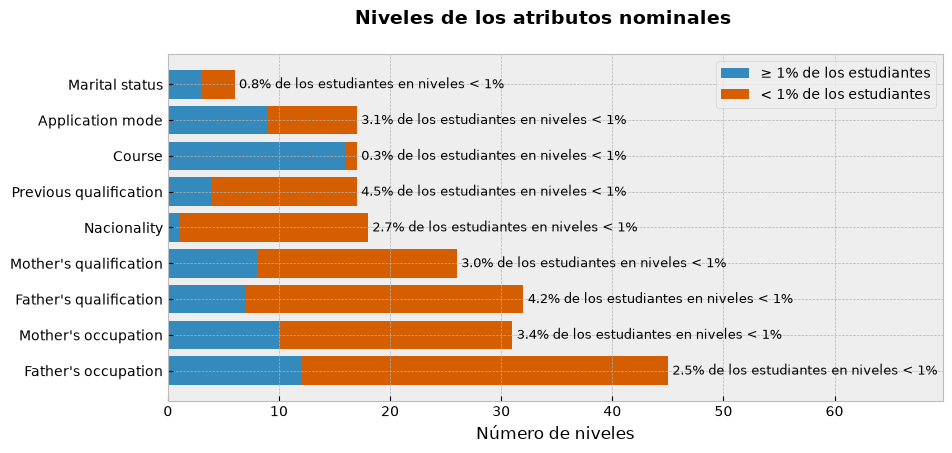

Estudiantes de prueba con al menos una categoría no vista en el entrenamiento: 12


In [7]:
frec = {c: entrena[c].value_counts(normalize=True) for c in cols_nominales}
infrecuentes = pd.DataFrame({
    'niveles': [frec[c].size for c in cols_nominales],
    'niveles < 1%': [(frec[c] < 0.01).sum() for c in cols_nominales],
    '% estudiantes en ellos': [frec[c][frec[c] < 0.01].sum() * 100 for c in cols_nominales],
    'no vistas en prueba': [sorted(set(prueba[c]) - set(entrena[c])) for c in cols_nominales]},
    index=cols_nominales)

with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(infrecuentes.index, infrecuentes['niveles'] - infrecuentes['niveles < 1%'], color='#348ABD', label='≥ 1% de los estudiantes')
    ax.barh(infrecuentes.index, infrecuentes['niveles < 1%'], left=infrecuentes['niveles'] - infrecuentes['niveles < 1%'],
            color='#D55E00', label='< 1% de los estudiantes')
    
    for i, (n, p) in enumerate(zip(infrecuentes['niveles'], infrecuentes['% estudiantes en ellos'])):
        ax.text(n + 0.4, i, f'{p:.1f}% de los estudiantes en niveles < 1%', va='center', fontsize=9)
        
    ax.set_xlim(0, infrecuentes['niveles'].max() * 1.55)
    ax.set_xlabel('Número de niveles')
    ax.invert_yaxis()
    ax.legend(loc='upper right')
    fig.suptitle('Niveles de los atributos nominales', fontweight='bold', fontsize=14)
    plt.show()


no_vistos = (~pd.concat([prueba[c].isin(entrena[c]) for c in cols_nominales], axis=1)).any(axis=1).sum()
print(f"Estudiantes de prueba con al menos una categoría no vista en el entrenamiento: {no_vistos}")

En seis de los nueve atributos nominales, la mayoría de los niveles tiene menos del 1% de los estudiantes. El caso extremo es `Nacionality`, con 17 de sus 18 niveles por debajo de ese umbral, pues casi todos los estudiantes son portugueses; le siguen `Father's occupation` (33 de 45) y `Father's qualification` (25 de 32). Aun así, en conjunto estos niveles solo representan entre el 0.3% y el 4.5% de los registros de cada atributo. Además, seis atributos del conjunto de prueba contienen categorías que no aparecen en el entrenamiento, en un total de 12 estudiantes. Ambos hechos deberán tomarse en cuenta al codificar los atributos nominales.

### 1.4. Información disponible para variable objetivo

La decisión se toma al cierre del primer semestre, por lo que solo se utilizan los 30 atributos conocidos en ese momento: los de la inscripción (perfil, antecedentes académicos y situación socioeconómica), los indicadores macroeconómicos del año de ingreso y el desempeño en el primer semestre. Los seis atributos del segundo semestre son información del futuro y no existen en el conjunto de prueba; se reservan únicamente para estimar, más adelante, cuánto se ganaría al esperar al cierre del segundo semestre.m

In [8]:
X = entrena[atributos]                     
X_2s = entrena[atributos + cols_2s]
y = entrena['Target']
X_prueba, id_prueba = prueba[atributos], prueba['id']

print(f"Atributos para decidir: {X.shape[1]} | Con el segundo semestre: {X_2s.shape[1]}")

Atributos para decidir: 30 | Con el segundo semestre: 36


Para darnos una idea de cuánto informa lo disponible al cierre del primer semestre, se grafican tres atributos por clase.

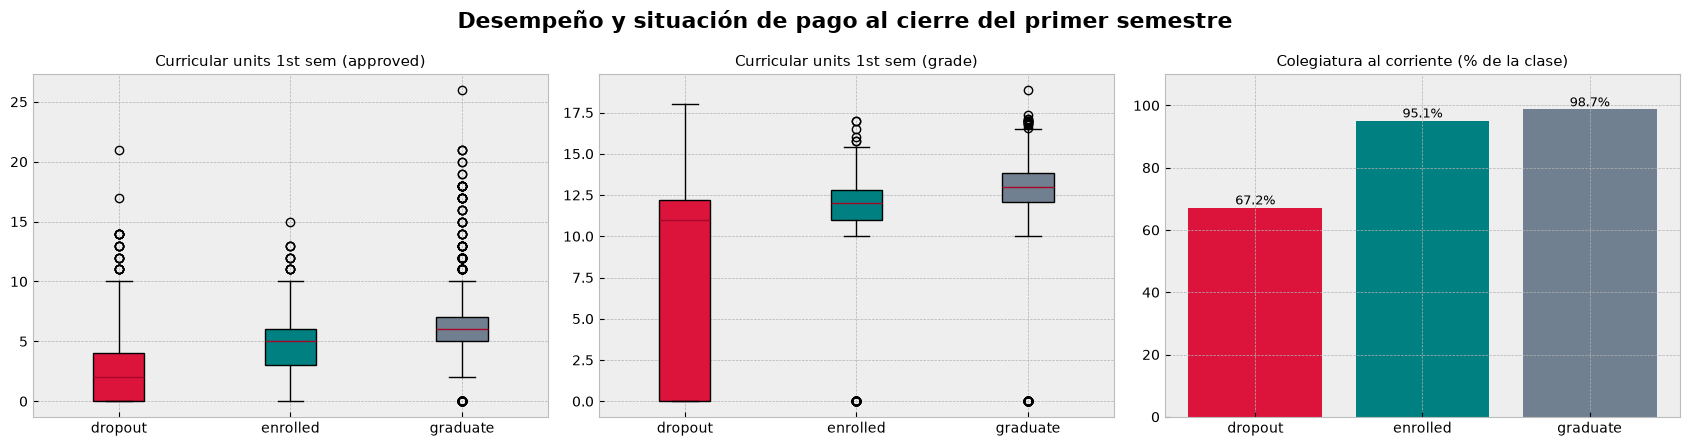

In [9]:
key = ['Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)']

with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    fig.suptitle('Desempeño y situación de pago al cierre del primer semestre', fontweight='bold', fontsize=16)

    for i in range(2):
        cajas = axes[i].boxplot([entrena.loc[y == c, key[i]] for c in orden_clases], patch_artist=True)
        for caja, c in zip(cajas['boxes'], orden_clases):
            caja.set_facecolor(colores_cl[c])
        axes[i].set_xticks(range(1, 4), orden_clases)
        axes[i].set_title(key[i], fontsize=11)

    al_corriente = entrena.groupby('Target')['Tuition fees up to date'].mean().reindex(orden_clases) * 100
    axes[2].bar(orden_clases, al_corriente.values, color=[colores_cl[c] for c in orden_clases])
    
    for j, v in enumerate(al_corriente.values):
        axes[2].text(j, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
        
    axes[2].set_ylim(0, 110)
    axes[2].set_title('Colegiatura al corriente (% de la clase)', fontsize=11)

    plt.tight_layout()
    plt.show()

El primer semestre ya separa bastante a los desertores: la mediana de unidades aprobadas es de 2, contra 5 de los inscritos y 6 de los graduados, y ~40% de los desertores no aprobó ninguna (de ahí que el primer cuartil de su calificación sea 0). Asimismo, dos tercios (~67%) de los desertores tiene la colegiatura al corriente, contra más del 95% en las otras dos clases. La clase inscrito queda entre las otras dos y se traslapa con ambas, por lo que se anticipa que será la más difícil de reconocer.

## 2. Preprocesamiento

Cada clasificador hace suposiciones distintas sobre los atributos, por lo que su preprocesamiento se define por separado, dentro de un `Pipeline`.

### 2.1. Manejando categorías poco frecuentes

Como se observó en la exploración, varios atributos nominales tienen una mayoría de niveles con muy pocos estudiantes y el conjunto de prueba contiene categorías que no aparecen en el entrenamiento.
Por ello, en todos los clasificadores, las categorías con menos del 1% de los estudiantes del entrenamiento, así como las no vistas, se agrupan en una sola categoría «infrecuente». El umbral de 1% (alrededor de 35 estudiantes, o 28 en cada pliegue de entrenamiento) conserva por separado a los niveles con suficientes estudiantes para estimar su efecto.

In [10]:
MIN_FREC = 0.01 # Proporción mínima de estudiantes para que una categoría se conserve por separado

def onehot():
    # One-hot
    return OneHotEncoder(min_frequency=MIN_FREC, handle_unknown='infrequent_if_exist', sparse_output=False)

codificador = onehot().fit(X[cols_nominales])
columnas_oh = list(codificador.get_feature_names_out())
prueba_oh = codificador.transform(X_prueba[cols_nominales])

agrupacion = pd.DataFrame({
    'niveles': [X[c].nunique() for c in cols_nominales],
    'niveles agrupados': [len(inf) for inf in codificador.infrequent_categories_],
    'columnas one-hot': [sum(n.startswith(c + '_') for n in columnas_oh) for c in cols_nominales],
    'estudiantes de prueba en «infrecuente»': [int(prueba_oh[:, columnas_oh.index(c + '_infrequent_sklearn')].sum())
                                               for c in cols_nominales]},
    index=cols_nominales)
agrupacion.loc['total'] = agrupacion.sum()
agrupacion

,niveles,niveles agrupados,columnas one-hot,estudiantes de prueba en «infrecuente»
Marital status,6,3,4,5
Application mode,17,8,10,24
Course,17,1,17,1
Previous qualification,17,13,5,39
Nacionality,18,17,2,15
Mother's qualification,26,18,9,26
Father's qualification,32,25,8,32
Mother's occupation,31,21,11,32
Father's occupation,45,33,13,25
total,209,139,79,199


 Con la agrupación, los 209 niveles de los nueve atributos nominales se representan con 79 columnas *one-hot*. Los atributos con más niveles raros son los que más se reduce.

### 2.2. Preprocesamiento general

Los cinco clasificadores comparten la misma estructura de preprocesamiento: los atributos nominales se codifican con *one-hot* (infrecuentes) y los binarios permanecen con los mismo valores. Lo único que cambia entre clasificadores es el tratamiento del ordinal y los numéricos, que se pasa como argumento; la lista de atributos numéricos también es un argumento, que se utilizará más adelante para añadir los del segundo semestre:

In [11]:
def preparar(numericos, cols_num=cols_ordinales + cols_numericas):
    return ColumnTransformer([('nominales', onehot(), cols_nominales),
                              ('binarios', 'passthrough', cols_binarias),
                              ('numericos', numericos, cols_num)])
    

### 2.3. Árbol de decisión

* Los nominales se codifican usando *one-hot* debido a que el árbol de scikit-learn no admite atributos categóricos.

In [12]:
def pipeline_arbol(**params):
    return Pipeline([('prep', preparar('passthrough')), ('modelo', DecisionTreeClassifier(random_state=ran, **params))])

### 2.4. Naive Bayes

Naive Bayes supone que los atributos son independientes dada la clase. Para que todos los atributos se modelen de la misma forma, se representan como indicadores 0/1:

* Nominales, one-hot y binarios, sin cambio.
* Ordinal y numéricos se discretizan dividiendo en intervalos con el mismo número de estudiantes y usando *one-hot* para codificar cada cuartil. La discretización evita suponer normalidad de la distribución de los datos que aparentan no seguir.

Sobre esta representación, la variante determina cómo se modelan los indicadores, y se elegirá en la búsqueda junto con el suavizado α: `BernoulliNB` modela la presencia y la ausencia de cada indicador; `MultinomialNB` solo los indicadores presentes, como si fueran conteos; y `ComplementNB` es una versión de la multinomial que estima los parámetros de cada clase con los estudiantes de las otras clases, pensada para clases desbalanceadas.

In [13]:

variantes_nb = {'bernoulli': BernoulliNB, 'multinomial': MultinomialNB, 'complement': ComplementNB}

def pipeline_nb(variante='bernoulli', n_bins=5, alpha=1.0):
    intervalos = KBinsDiscretizer(n_bins=n_bins, encode='onehot-dense', strategy='quantile', quantile_method='averaged_inverted_cdf')
    return Pipeline([('prep', preparar(intervalos)), ('modelo', variantes_nb[variante](alpha=alpha))])

### 2.5. k vecinos más cercanos (kNN)

kNN clasifica a cada estudiante según sus vecinos más cercanos, por lo que el preprocesamiento debe hacer que las distancias sean comparables entre atributos:

* Nominales, *one-hot* con los códigos.
* Binarios, sin cambio.
* Ordinal y numéricos se estandarizan (media 0, desviación 1), sin escalar.

In [14]:
def pipeline_knn(**params):
    return Pipeline([('prep', preparar(StandardScaler())), ('modelo', KNeighborsClassifier(**params))])

### 2.6. Máquinas de soporte vectorial (SVM)

El SVM utiliza el mismo preprocesamiento que kNN:

* Nominales, *one-hot* y binarios, sin cambio.
* Ordinal y numéricos se estandarizan.

In [15]:
def pipeline_svm(**params):
    return Pipeline([('prep', preparar(StandardScaler())), ('modelo', SVC(random_state=ran, **params))])

### 2.7. Regresión logística

* Nominales se codifican usando *one-hot*
* Binarios, sin cambio.
* Ordinal y numéricos se estandarizan, la regularización actúa sobre la magnitud de los coeficientes.

In [16]:
def pipeline_logistica(**params):
    modelo = LogisticRegression(solver='saga', tol=1e-3, max_iter=5000, random_state=ran, **params)
    return Pipeline([('prep', preparar(StandardScaler())), ('modelo', modelo)])

### 2.8. Estratificación 

Se ajusta el preprocesamiento de cada pipeline.

In [17]:
pipelines = {
    'Árbol de decisión': pipeline_arbol,
    'Naive Bayes': pipeline_nb,
    'kNN': pipeline_knn,
    'SVM': pipeline_svm,
    'Regresión logística': pipeline_logistica,
}

Se fijan los pliegues de la validación cruzada estratificada que se utilizarán con los cinco clasificadores en las secciones siguientes. Dado que no hay registros duplicados, no se requiere agrupar los pliegues.

In [18]:
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=ran)

## 3. Optimización de hiperparámetros

Los hiperparámetros se optimizan con una búsqueda bayesiana, mediante Optuna y su muestreador TPE (*Tree-structured Parzen Estimator*). Optuna separa las configuraciones con mejor F1 macro de las demás, estima una densidad para cada grupo y propone la configuración con mayor razón entre ambas. Las primeras 10 configuraciones se eligen al azar, para tener un punto de partida.

Cada configuración se evalúa con el F1 macro promedio de la validación cruzada estratificada sobre el conjunto de entrenamiento, con los mismos cinco pliegues para los cinco clasificadores, y se evalúan 55 configuraciones por clasificador. Los hiperparámetros cuyo efecto depende del orden de magnitud (C, gamma, α, `ccp_alpha`, k) se muestrean en escala logarítmica.

Después de cada búsqueda se grafica el F1 macro de validación de cada configuración (puntos) y el mejor alcanzado hasta ese momento (línea) contra el número de configuraciones evaluadas; la línea vertical marca la primera configuración que quedó a menos de 0.005 del mejor valor final, a partir de la cual la búsqueda se encuentra en una meseta:

In [19]:
N_CONFIG = 55 # Configuraciones evaluadas por clasificador
optuna.logging.set_verbosity(optuna.logging.WARNING)

def optimizar(espacio, n_trials=N_CONFIG):
    # Búsqueda bayesiana (TPE): `espacio` recibe un t de Optuna y devuelve el pipeline con la configuración propuesta
    def objetivo(t):
        f1 = cross_validate(espacio(t), X, y, cv=pliegues, scoring='f1_macro')['test_score']
        t.set_user_attr('f1_pliegues', f1.tolist())
        return f1.mean()

    estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=ran))
    t0 = perf_counter()
    estudio.optimize(objetivo, n_trials=n_trials)
    estudio.set_user_attr('tiempo', perf_counter() - t0)
    return estudio

def reporta(estudio):
    mejor = estudio.best_trial
    f1 = np.array(mejor.user_attrs['f1_pliegues'])
    print(f"{len(estudio.trials)} configuraciones en {estudio.user_attrs['tiempo']:.0f} s")
    print(f"Mejor F1 macro: {f1.mean():.3f} +- {f1.std():.3f} (configuración {mejor.number + 1})")
    print("Hiperparámetros:", {k: (float(f'{v:.3g}') if isinstance(v, float) else v) for k, v in mejor.params.items()})

TOLERANCIA = 0.005
colores_clf = {'Árbol de decisión': '#348ABD', 'Naive Bayes': '#7A68A6', 'kNN': '#467821',
               'SVM': '#D55E00', 'Regresión logística': '#A60628'}

def meseta(nombre, estudio):
    # F1 macro de cada configuración y el mejor alcanzado hasta ese momento, contra el número de configuraciones evaluadas
    valores = np.array([t.value for t in estudio.trials])
    mejor = np.maximum.accumulate(valores)
    n = np.arange(1, len(valores) + 1)
    n_meseta = int(np.argmax(mejor >= mejor[-1] - TOLERANCIA)) + 1
    piso = max(valores.min(), mejor[-1] - 0.12) - 0.005

    with plt.style.context('bmh'):
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.scatter(n, valores, s=16, color='slategrey', alpha=0.5, label='configuración')
        ax.step(n, mejor, where='post', color=colores_clf[nombre], linewidth=2.2, label='mejor hasta el momento')
        ax.axvline(n_meseta, color='black', linestyle='--', linewidth=1)
        ax.text(n_meseta + 0.6, mejor[-1] + 0.004, f'configuración {n_meseta}', fontsize=9)
        ax.set_ylim(piso, mejor[-1] + 0.015)
        ax.set_xlabel('Configuraciones evaluadas')
        ax.set_ylabel('F1 macro de validación')
        ax.legend(loc='lower right', fontsize=9)
        fig.suptitle(f'Convergencia de la búsqueda | {nombre}', fontweight='bold', fontsize=13)
        plt.show()

espacios, estudios = {}, {}

### 3.1. Árbol de decisión

55 configuraciones en 34 s
Mejor F1 macro: 0.642 +- 0.007 (configuración 7)
Hiperparámetros: {'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 17, 'ccp_alpha': 0.000177, 'class_weight': 'balanced'}


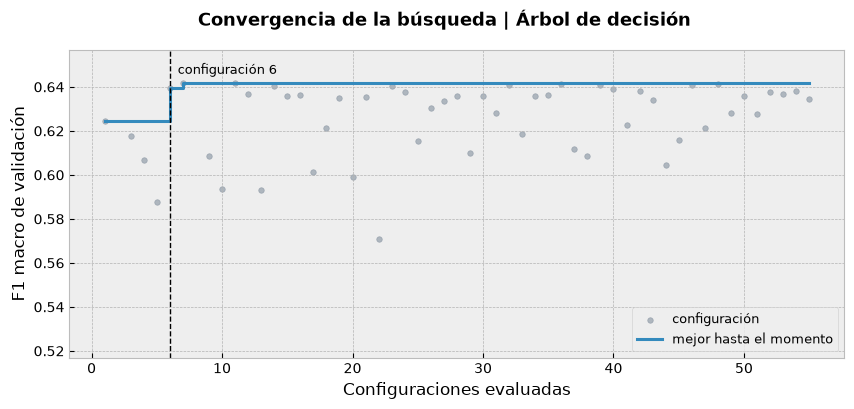

In [20]:
def espacio_arbol(t):
    return pipeline_arbol(
        criterion=t.suggest_categorical('criterion', ['gini', 'entropy']),
        max_depth=t.suggest_int('max_depth', 2, 30),
        min_samples_leaf=t.suggest_int('min_samples_leaf', 1, 100, log=True),
        ccp_alpha=t.suggest_float('ccp_alpha', 1e-5, 1e-1, log=True),
        class_weight=t.suggest_categorical('class_weight', [None, 'balanced']))

espacios['Árbol de decisión'] = espacio_arbol
estudios['Árbol de decisión'] = optimizar(espacio_arbol)
reporta(estudios['Árbol de decisión'])
meseta('Árbol de decisión', estudios['Árbol de decisión'])

El mejor F1 macro sube rápidamente durante las primeras configuraciones (a ~0.64 en 6-7). La mejor configuración alcanza un F1 Macro de 0.642 con una varianza de 0.007.

### 3.2. Naive Bayes

55 configuraciones en 37 s
Mejor F1 macro: 0.621 +- 0.009 (configuración 12)
Hiperparámetros: {'variante': 'bernoulli', 'n_bins': 8, 'alpha': 0.00419}


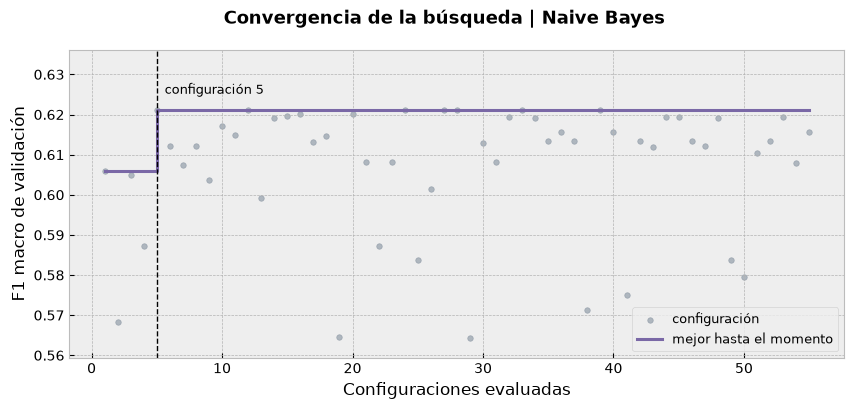

In [21]:
warnings.filterwarnings('ignore', message='Bins whose width are too small')
warnings.filterwarnings('ignore', message='Feature .* is constant')
def espacio_nb(t):
    return pipeline_nb(variante=t.suggest_categorical('variante', ['bernoulli', 'multinomial', 'complement']),
                       n_bins=t.suggest_int('n_bins', 2, 20),
                       alpha=t.suggest_float('alpha', 1e-3, 10, log=True))

espacios['Naive Bayes'] = espacio_nb
estudios['Naive Bayes'] = optimizar(espacio_nb)
reporta(estudios['Naive Bayes'])
meseta('Naive Bayes', estudios['Naive Bayes'])

Naive Bayes alcanza la meseta casi de inmediato: desde la quinta configuración obtiene ~0.62, el resto mejoran marginalmente. La mejor configuración (núm. 12) utilizando un modelado de distribución Bernoulli. 

### 3.3. k vecinos más cercanos (kNN)

55 configuraciones en 22 s
Mejor F1 macro: 0.579 +- 0.012 (configuración 11)
Hiperparámetros: {'n_neighbors': 8, 'weights': 'uniform', 'p': 1}


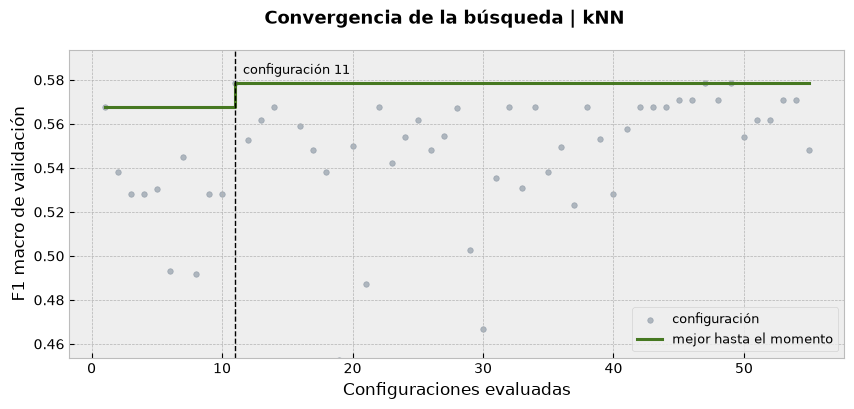

In [22]:
def espacio_knn(t):
    return pipeline_knn(
        n_neighbors=t.suggest_int('n_neighbors', 1, 200, log=True),
        weights=t.suggest_categorical('weights', ['uniform', 'distance']),
        p=t.suggest_categorical('p', [1, 2]))

espacios['kNN'] = espacio_knn
estudios['kNN'] = optimizar(espacio_knn)
reporta(estudios['kNN'])
meseta('kNN', estudios['kNN'])

kNN muestra la mayor dispersión entre configuraciones, pues su desempeño depende casi por completo del número de vecinos. El mejor resultado toma en cuenta a solo 8 vecinos. La meseta se alcanza justo después de esta configuración y a partir de ese punto, la mejora es marginal.

### 3.4. Máquinas de soporte vectorial (SVM)

Con el *kernel* lineal, el rango de `C` llega solo hasta 10 (`C_lineal`), pues con valores mayores el optimizador de `SVC` tarda varios minutos por configuración sin cambiar el F1 macro:

55 configuraciones en 307 s
Mejor F1 macro: 0.683 +- 0.008 (configuración 52)
Hiperparámetros: {'kernel': 'rbf', 'class_weight': 'balanced', 'C': 10.2, 'gamma': 0.00407}


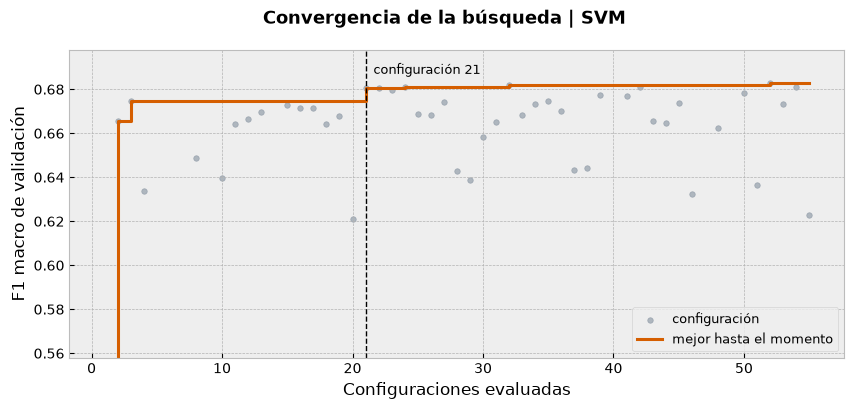

In [23]:
def espacio_svm(t):
    kernel = t.suggest_categorical('kernel', ['linear', 'rbf', 'poly'])
    params = {'kernel': kernel, 'class_weight': t.suggest_categorical('class_weight', [None, 'balanced'])}
    if kernel == 'linear':
        params['C'] = t.suggest_float('C_lineal', 1e-3, 10, log=True)
    else:
        params['C'] = t.suggest_float('C', 1e-2, 1e2, log=True)
        params['gamma'] = t.suggest_float('gamma', 1e-4, 1, log=True)
        if kernel == 'poly':
            params['degree'] = t.suggest_categorical('degree', [2, 3])
    return pipeline_svm(**params)

espacios['SVM'] = espacio_svm
estudios['SVM'] = optimizar(espacio_svm)
reporta(estudios['SVM'])
meseta('SVM', estudios['SVM'])

La primera configuración, elegida al azar, predice una sola clase. Las configuraciones siguientes alcanzan rápidamente un desempeño alto, pero la meseta llega en la configuración 21; a partir de ahí, la mejora es marginal. El mejor resultado, en la configuración 52, utiliza un kernel RBF con pesos balanceados.

### 3.5. Regresión logística

En esta versión de scikit-learn, el tipo de regularización se controla con `l1_ratio`: 0 corresponde a L2, 1 a L1 y un valor intermedio a *elastic net*:

55 configuraciones en 413 s
Mejor F1 macro: 0.683 +- 0.010 (configuración 54)
Hiperparámetros: {'regularizacion': 'elastic net', 'l1_ratio': 0.311, 'C': 0.0953, 'class_weight': 'balanced'}


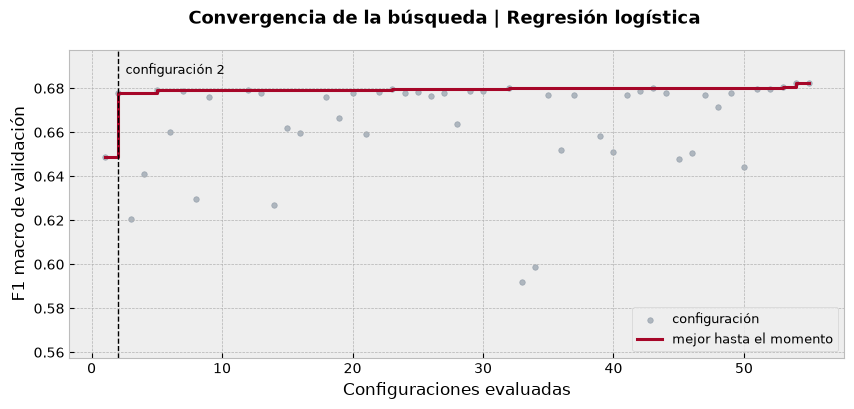

In [24]:
def espacio_logistica(t):
    tipo = t.suggest_categorical('regularizacion', ['L2', 'L1', 'elastic net'])
    if tipo == 'elastic net':
        l1_ratio = t.suggest_float('l1_ratio', 0.1, 0.9)
    else:
        l1_ratio = 0.0 if tipo == 'L2' else 1.0
    return pipeline_logistica(
        C=t.suggest_float('C', 1e-4, 1e2, log=True), l1_ratio=l1_ratio,
        class_weight=t.suggest_categorical('class_weight', [None, 'balanced']))

espacios['Regresión logística'] = espacio_logistica
estudios['Regresión logística'] = optimizar(espacio_logistica)
reporta(estudios['Regresión logística'])
meseta('Regresión logística', estudios['Regresión logística'])

La regresión logística alcanza la meseta más rápido que el resto de los clasificadores, y a partir de ahí la mejora es marginal. Casi todas las configuraciones obtienen un desempeño muy similar; las pocas que quedan por debajo no utilizan pesos por clase o tienen una regularización tan fuerte que el modelo deja de distinguir a las clases.

### 3.6. Resumen

Además de la mejor configuración, se estima qué hiperparámetro influye más en el F1 macro de cada clasificador, con la importancia fANOVA de Optuna: un bosque aleatorio aprende a predecir el F1 macro a partir de los hiperparámetros evaluados, y la importancia de cada uno es la fracción de la varianza del F1 macro que explica. Solo se consideran los hiperparámetros presentes en todas las configuraciones.

In [25]:
from optuna.importance import FanovaImportanceEvaluator, get_param_importances

importancias = {nombre: get_param_importances(e, evaluator=FanovaImportanceEvaluator(seed=ran))
                for nombre, e in estudios.items()}

def formato(params):
    return ', '.join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items())

resumen_busqueda = pd.DataFrame({
    nombre: {'configuraciones': len(e.trials),
             'F1 macro': e.best_value,
             'desv. est.': np.std(e.best_trial.user_attrs['f1_pliegues']),
             'tiempo (s)': e.user_attrs['tiempo'],
             'más influyente': f"{next(iter(importancias[nombre]))} ({next(iter(importancias[nombre].values())):.0%})",
             'mejor configuración': formato(e.best_params)}
    for nombre, e in estudios.items()}).T

pd.set_option('display.max_colwidth', None)
resumen_busqueda

,configuraciones,F1 macro,desv. est.,tiempo (s),más influyente,mejor configuración
Árbol de decisión,55,0.641913,0.006935,33.695106,ccp_alpha (87%),"criterion=entropy, max_depth=9, min_samples_leaf=17, ccp_alpha=0.000177, class_weight=balanced"
Naive Bayes,55,0.621157,0.008631,37.13918,variante (97%),"variante=bernoulli, n_bins=8, alpha=0.00419"
kNN,55,0.578737,0.011644,21.730669,n_neighbors (95%),"n_neighbors=8, weights=uniform, p=1"
SVM,55,0.682992,0.007888,307.314395,kernel (94%),"kernel=rbf, class_weight=balanced, C=10.2, gamma=0.00407"
Regresión logística,55,0.682526,0.009827,412.802371,class_weight (94%),"regularizacion=elastic net, l1_ratio=0.311, C=0.0953, class_weight=balanced"


## 4. Comparación de los clasificadores

Los cinco clasificadores se comparan con su mejor configuración. El F1 macro (media y desviación estándar) corresponde a los cinco pliegues de esa configuración. La sensibilidad y la especificidad de cada clase se calculan con las predicciones de validación cruzada sobre los mismos pliegues:

In [26]:
modelos_opt = {nombre: espacios[nombre](optuna.trial.FixedTrial(e.best_params)) for nombre, e in estudios.items()}
pred_cv = {nombre: cross_val_predict(modelo, X, y, cv=pliegues) for nombre, modelo in modelos_opt.items()}

def sens_espec(y_real, pred):
    conteos = pd.DataFrame([{'TN': m[0, 0], 'FP': m[0, 1], 'FN': m[1, 0], 'TP': m[1, 1]}
                            for m in multilabel_confusion_matrix(y_real, pred, labels=orden_clases)], index=orden_clases)
    return pd.DataFrame({'sensibilidad': conteos['TP'] / (conteos['TP'] + conteos['FN']),
                         'especificidad': conteos['TN'] / (conteos['TN'] + conteos['FP'])})

filas = {}
for nombre, e in estudios.items():
    f1 = np.array(e.best_trial.user_attrs['f1_pliegues'])
    se = sens_espec(y, pred_cv[nombre])
    fila = {('F1 macro', 'media'): f1.mean(), ('F1 macro', 'desv. est.'): f1.std()}
    fila.update({('sensibilidad', c): se.loc[c, 'sensibilidad'] for c in orden_clases})
    fila.update({('especificidad', c): se.loc[c, 'especificidad'] for c in orden_clases})
    fila.update({('búsqueda', 'tiempo (s)'): e.user_attrs['tiempo'], ('búsqueda', 's / config.'): e.user_attrs['tiempo'] / len(e.trials)})
    filas[nombre] = fila

comparacion = pd.DataFrame(filas).T.sort_values(('F1 macro', 'media'), ascending=False)

comparacion

F1 macro            sensibilidad                      \
                        media desv. est.      dropout  enrolled  graduate   
SVM                  0.682992   0.007888     0.662269  0.609449  0.804188   
Regresión logística  0.682526   0.009827     0.698329  0.570079  0.798529   
Árbol de decisión    0.641913   0.006935     0.632366  0.579528  0.744765   
Naive Bayes          0.621157   0.008631     0.704485  0.418898  0.748161   
kNN                  0.578737   0.011644     0.598065  0.223622  0.897001   

                    especificidad                        búsqueda              
                          dropout  enrolled  graduate  tiempo (s) s / config.  
SVM                      0.933389  0.816460  0.839165  307.314395    5.587534  
Regresión logística      0.921316  0.827824  0.840293  412.802371    7.505498  
Árbol de decisión        0.920483  0.768595  0.845937   33.695106    0.612638  
Naive Bayes              0.828060  0.867080  0.801919   37.139180    0.675258  
kNN                      0.900500  0.934573  0.603273   21.730669    0.395103

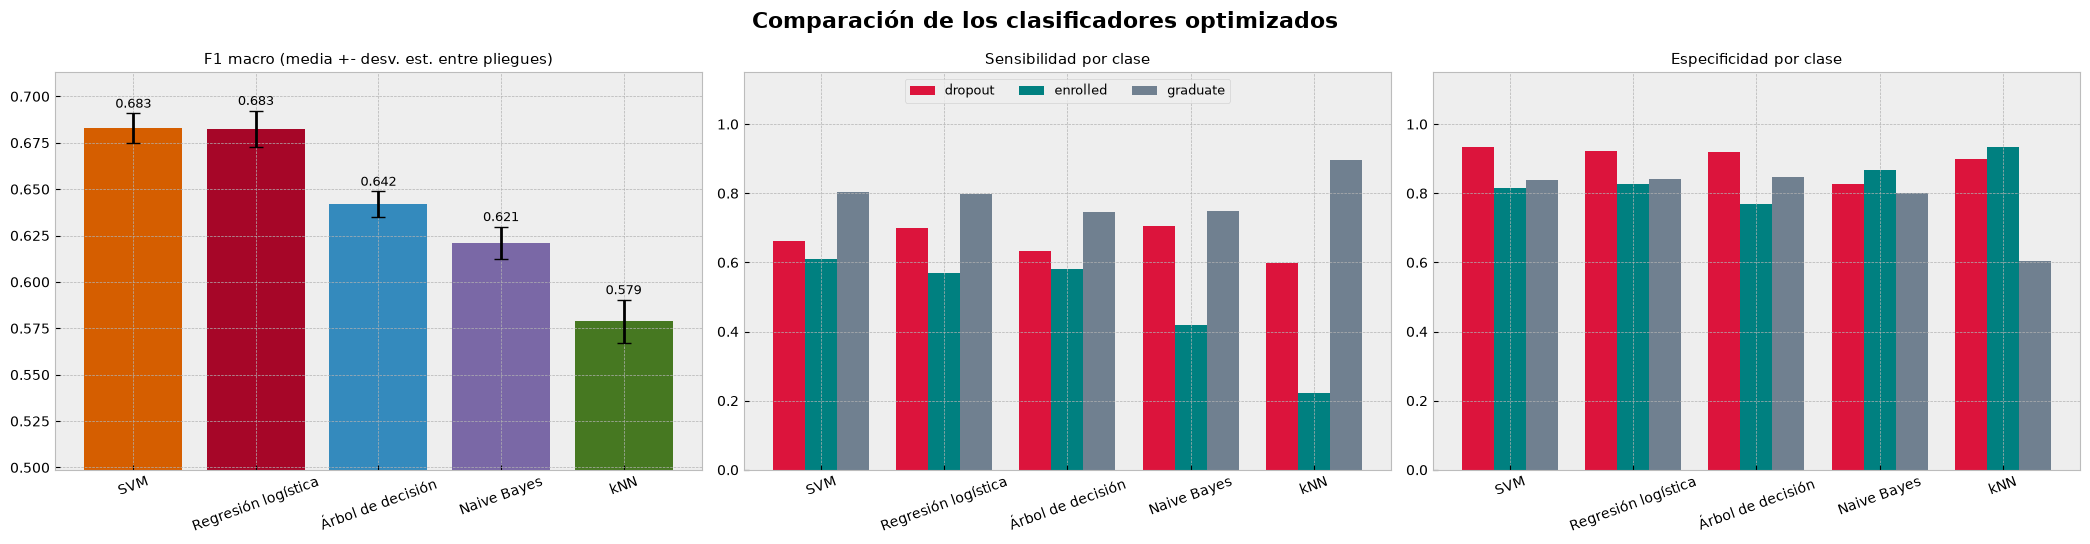

In [27]:
orden_clf = comparacion.index.tolist()
ancho = 0.26

with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

    # F1 macro con la desviación estándar entre pliegues
    medias, desv = comparacion[('F1 macro', 'media')], comparacion[('F1 macro', 'desv. est.')]
    axes[0].bar(orden_clf, medias, yerr=desv, capsize=5, color=[colores_clf[n] for n in orden_clf])
    for i, (m, d) in enumerate(zip(medias, desv)):
        axes[0].text(i, m + d + 0.003, f'{m:.3f}', ha='center', fontsize=9)
    axes[0].set_ylim(medias.min() - 0.08, medias.max() + 0.03)
    axes[0].set_title('F1 macro (media +- desv. est. entre pliegues)', fontsize=11)

    # Sensibilidad y especificidad por clase
    for ax, metrica in zip(axes[1:], ['sensibilidad', 'especificidad']):
        for k, c in enumerate(orden_clases):
            v = comparacion[(metrica, c)]
            ax.bar(np.arange(len(orden_clf)) + (k - 1) * ancho, v, width=ancho, color=colores_cl[c], label=c)
        ax.set_xticks(range(len(orden_clf)), orden_clf)
        ax.set_ylim(0, 1.15)
        ax.set_title(f'{metrica.capitalize()} por clase', fontsize=11)
    axes[1].legend(loc='upper center', ncol=3, fontsize=9)

    for ax in axes:
        ax.tick_params(axis='x', labelrotation=20)
    fig.suptitle('Comparación de los clasificadores optimizados', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

El SVM y la regresión logística obtienen el mejor F1 macro, ambos de 0.683. Su diferencia es mucho menor que la variación entre pliegues, por lo que no se distinguen entre sí. Los dos utilizan pesos balanceados; el SVM, con un kernel RBF de gamma pequeño, y la regresión logística, con regularización elastic net. Les siguen el árbol (0.642), Naive Bayes (0.621) y kNN (0.579). Cabe destacar que cada F1 macro es el de la mejor de 55 configuraciones evaluadas con los mismos pliegues, por lo que es ligeramente optimista, aunque lo es por igual para los cinco.

La sensibilidad por clase muestra que graduate es la clase que mejor se reconoce y enrolled la más difícil. Aunque empatan en F1 macro, la regresión logística reconoce a más desertores que el SVM (0.698 contra 0.662), mientras que el SVM reconoce a más inscritos (0.609 contra 0.570). kNN muestra un sesgo hacia la clase mayoritaria: reconoce al 90% de los graduados, pero solo al 22% de los inscritos.

En cuanto al tiempo, la búsqueda del SVM y la de la regresión logística tomaron alrededor de 5 y 7 minutos, respectivamente, contra unos 30 segundos del árbol, Naive Bayes y kNN. El árbol es unas diez veces más rápido de optimizar que el SVM, a cambio de 0.04 menos de F1 macro.

## 5. Matriz de confusión del SVM

El mejor clasificador de acuerdo con el F1 macro de validación es el SVM, prácticamente empatado con la regresión logística. Su matriz de confusión se construye con las predicciones de validación cruzada de la sección anterior, de modo que cada estudiante es clasificado por un modelo que no lo vio durante el entrenamiento. Se muestran los conteos y la proporción de cada clase real, cuya diagonal corresponde a la sensibilidad:

In [28]:
print(pred_cv)

{'Árbol de decisión': array(['graduate', 'graduate', 'dropout', ..., 'enrolled', 'dropout',
       'graduate'], shape=(3539,), dtype=object), 'Naive Bayes': array(['graduate', 'graduate', 'dropout', ..., 'graduate', 'dropout',
       'graduate'], shape=(3539,), dtype='<U8'), 'kNN': array(['graduate', 'graduate', 'dropout', ..., 'graduate', 'dropout',
       'graduate'], shape=(3539,), dtype=object), 'SVM': array(['graduate', 'graduate', 'enrolled', ..., 'graduate', 'dropout',
       'graduate'], shape=(3539,), dtype=object), 'Regresión logística': array(['graduate', 'graduate', 'enrolled', ..., 'graduate', 'dropout',
       'graduate'], shape=(3539,), dtype=object)}


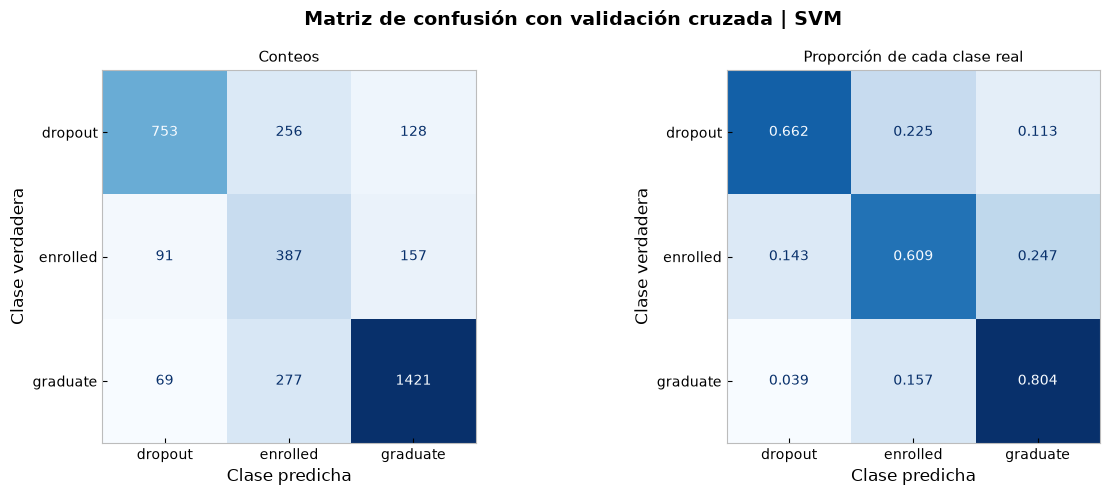

In [29]:
mejor_clf = comparacion.index[0]
pred_mejor = pred_cv[mejor_clf]

with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, normalizar, titulo, formato in [(axes[0], None, 'Conteos', 'd'), (axes[1], 'true', 'Proporción de cada clase real', '.3f')]:
        ConfusionMatrixDisplay.from_predictions(y, pred_mejor, labels=orden_clases, normalize=normalizar,
                                                values_format=formato, cmap='Blues', colorbar=False, ax=ax)
        ax.set_title(titulo, fontsize=11)
        ax.set_xlabel('Clase predicha')
        ax.set_ylabel('Clase verdadera')
        ax.grid(False)
    fig.suptitle(f'Matriz de confusión con validación cruzada | {mejor_clf}', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

De los 1,137 desertores, el SVM reconoce a 753 (66.2%). De los 384 que se le escapan, 256 se clasifican como inscritos y 128 como graduados, es decir, el desertor se confunde principalmente con el inscrito (dos de cada tres errores). En sentido inverso, de los 913 estudiantes que el modelo predice como desertores, 753 lo son realmente, por lo que más de 4 de cada 5 alertas de deserción son correctas, y casi ningún graduado se confunde con un desertor. La clase inscrito sigue siendo la más difícil: se reconoce a ~60% y el resto se reparte entre graduados y desertores.

Para entender qué distingue a los desertores que el modelo reconoce de aquellos con los que se equivoca, primero se mide en qué atributos se apoya el SVM para reconocer a la clase desertor. Como el kernel RBF no tiene coeficientes, se utiliza la importancia por permutación: en cada pliegue de validación se revuelven los valores de un atributo y se mide cuánto cae el F1 de la clase desertor. Mientras más cae, más depende el modelo de ese atributo:

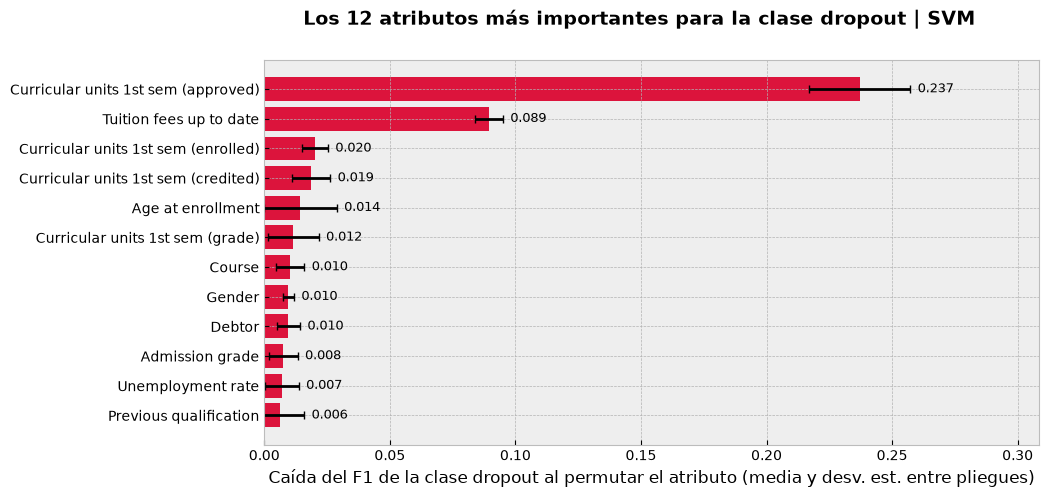

In [30]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

# El SVM con kernel RBF no tiene coeficientes: la importancia de cada atributo se mide por permutación, como la caída
# del F1 de la clase dropout al revolver ese atributo, en los pliegues de validación (estudiantes que el modelo no vio)
f1_dropout = make_scorer(f1_score, labels=['dropout'], average='macro')
importancias_perm = []
for i_ent, i_val in pliegues.split(X, y):
    modelo_svm = clone(modelos_opt[mejor_clf]).fit(X.iloc[i_ent], y.iloc[i_ent])
    r = permutation_importance(modelo_svm, X.iloc[i_val], y.iloc[i_val], scoring=f1_dropout, n_repeats=5, random_state=ran)
    importancias_perm.append(r.importances_mean)
importancias_perm = pd.DataFrame(importancias_perm, columns=X.columns)
top_perm = importancias_perm.mean().sort_values().tail(12)
error_perm = importancias_perm.std()[top_perm.index]

with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(top_perm.index, top_perm.values, xerr=error_perm.values, capsize=3, color='crimson')
    for i, v in enumerate(top_perm.values):
        ax.text(v + error_perm.iloc[i] + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0, (top_perm + error_perm).max() * 1.2)
    ax.set_xlabel('Caída del F1 de la clase dropout al permutar el atributo (media y desv. est. entre pliegues)')
    fig.suptitle(f'Los 12 atributos más importantes para la clase dropout | {mejor_clf}', fontweight='bold', fontsize=14)
    plt.show()

El SVM depende sobre todo de las unidades aprobadas en el primer semestre: al revolverlas, el F1 de la clase desertor cae 0.24. Le sigue tener la colegiatura al corriente, con una caída de 0.09, y muy por detrás, con caídas de 0.02 o menos, las unidades inscritas y acreditadas, la edad y la calificación del primer semestre; el resto de los atributos casi no influye. Es decir, el modelo reconoce a los desertores principalmente por un primer semestre con pocas unidades aprobadas y pagos atrasados. Cabe destacar que, cuando dos atributos están relacionados, revolver solo uno subestima su importancia, pues el modelo puede apoyarse en el otro.

Con base en lo anterior, se compara a los desertores según la clase que el modelo les asignó (bien clasificados, confundidos con inscritos y confundidos con graduados) contra todos los estudiantes que realmente siguen inscritos o se graduaron, en los atributos de mayor peso. Solo como referencia, se incluyen las unidades aprobadas en el segundo semestre, que no están disponibles al momento de decidir:

In [31]:
grupo = pd.Series(np.where(y == 'dropout', 'dropout → ' + pred_mejor, y + ' (todos)'), index=y.index)
orden_grupos = ['dropout → dropout', 'dropout → enrolled', 'dropout → graduate', 'enrolled (todos)', 'graduate (todos)']

perfil_df = pd.DataFrame({
    'grupo': grupo,
    'aprobadas 1er sem.': entrena['Curricular units 1st sem (approved)'],
    '% aprobado 1er sem.': 100 * entrena['Curricular units 1st sem (approved)'] / entrena['Curricular units 1st sem (enrolled)'].replace(0, np.nan),
    'calificación 1er sem.': entrena['Curricular units 1st sem (grade)'],
    '% sin aprobar ninguna': 100 * (entrena['Curricular units 1st sem (approved)'] == 0),
    '% colegiatura al corriente': 100 * entrena['Tuition fees up to date'],
    '% deudores': 100 * entrena['Debtor'],
    '% becados': 100 * entrena['Scholarship holder'],
    'edad': entrena['Age at enrollment'],
    'aprobadas 2do sem.': entrena['Curricular units 2nd sem (approved)']})

In [32]:
# Probabilidad de deserción de validación cruzada, solo si el clasificador la proporciona (SVC únicamente con probability=True);
# las columnas de predict_proba siguen el orden alfabético de las clases, igual que orden_clases
if hasattr(modelos_opt[mejor_clf], 'predict_proba'):
    proba_cv = cross_val_predict(modelos_opt[mejor_clf], X, y, cv=pliegues, method='predict_proba')
    perfil_df.insert(perfil_df.shape[1] - 1, 'P(dropout)', proba_cv[:, orden_clases.index('dropout')])

# Porcentajes para los atributos binarios y medianas para los demás
binarios_perfil = ['% sin aprobar ninguna', '% colegiatura al corriente', '% deudores', '% becados']
perfil = perfil_df.groupby('grupo').agg(
    {c: ('mean' if c in binarios_perfil else 'median') for c in perfil_df.columns if c != 'grupo'}).reindex(orden_grupos)
perfil.insert(0, 'estudiantes', grupo.value_counts().reindex(orden_grupos))
perfil.round(2)

,estudiantes,aprobadas 1er sem.,% aprobado 1er sem.,calificación 1er sem.,% sin aprobar ninguna,% colegiatura al corriente,% deudores,% becados,edad,aprobadas 2do sem.
grupo,,,,,,,,,,
dropout → dropout,753,0.0,0.00,0.00,56.84,51.93,29.48,6.37,26.0,0.0
dropout → enrolled,256,4.0,66.67,11.71,5.86,96.88,8.98,9.77,20.0,3.0
dropout → graduate,128,6.0,100.00,12.89,3.91,97.66,7.81,28.91,19.0,5.0
enrolled (todos),635,5.0,80.00,12.00,8.98,95.12,11.18,16.54,20.0,4.0
graduate (todos),1767,6.0,100.00,13.00,3.68,98.70,4.30,38.09,19.0,6.0


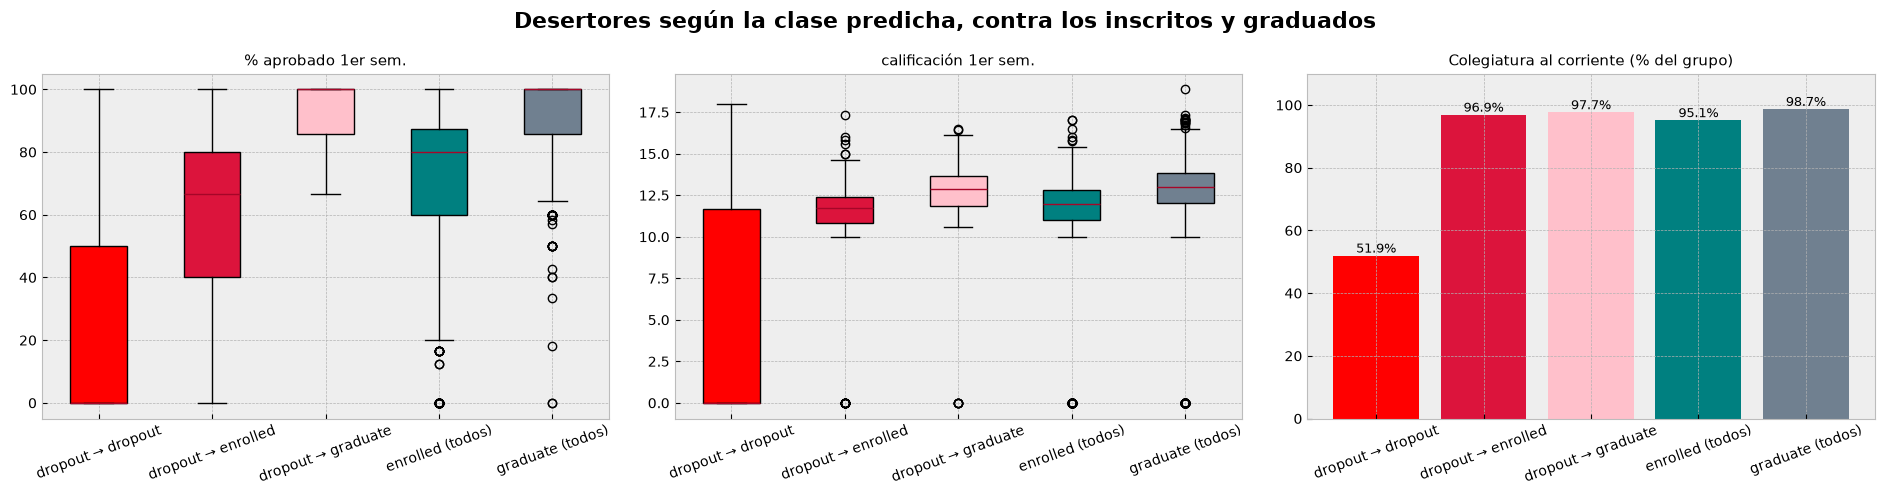

In [33]:
colores_grupo = ['red', 'crimson', 'pink', 'teal', 'slategrey']
key = ['% aprobado 1er sem.', 'calificación 1er sem.']

with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    fig.suptitle('Desertores según la clase predicha, contra los inscritos y graduados', fontweight='bold', fontsize=16)

    for i in range(2):
        cajas = axes[i].boxplot([perfil_df.loc[perfil_df['grupo'] == g, key[i]].dropna() for g in orden_grupos], patch_artist=True)
        for caja, color in zip(cajas['boxes'], colores_grupo):
            caja.set_facecolor(color)
        axes[i].set_xticks(range(1, 6), orden_grupos, rotation=20)
        axes[i].set_title(key[i], fontsize=11)

    axes[2].bar(orden_grupos, perfil['% colegiatura al corriente'], color=colores_grupo)
    for j, v in enumerate(perfil['% colegiatura al corriente']):
        axes[2].text(j, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
    axes[2].set_ylim(0, 110)
    axes[2].tick_params(axis='x', labelrotation=20)
    axes[2].set_title('Colegiatura al corriente (% del grupo)', fontsize=11)

    plt.tight_layout()
    plt.show()

La tabla y las gráficas explican la confusión. Los desertores que el modelo reconoce tienen un primer semestre claramente deficiente: más de la mitad no aprobó ninguna unidad (56.8%) y solo la mitad tiene la colegiatura al corriente (51.9%). En cambio, los desertores confundidos con inscritos aprueban dos tercios de lo que inscriben, con una calificación de 11.7, y casi todos están al corriente con sus pagos, prácticamente el mismo perfil de los inscritos. Los confundidos con graduados aprueban todo lo que inscriben, con una calificación de 12.9 y pocos deudores, cifras muy parecidas a las de los graduados. Además, ambos grupos son tan jóvenes como los inscritos y los graduados (de 19 a 20 años, contra 26 de los desertores reconocidos). Es decir, al cierre del primer semestre estos estudiantes no muestran señales de deserción en los datos.

Esto tiene dos explicaciones. La primera es que su deserción se manifiesta después: en el segundo semestre, los confundidos con inscritos bajan a 3 unidades aprobadas, contra 4 de los inscritos, y los confundidos con graduados a 5, contra 6 de los graduados, una señal que el modelo no puede ver al decidir. La segunda es la propia definición de la clase: dropout incluye los cambios de carrera o de institución, por lo que un estudiante con buen desempeño que se cambia de programa queda etiquetado como desertor, aunque académicamente sea igual a un graduado. La confusión con los inscritos es la más frecuente porque ambas clases comparten un avance más lento que el de los graduados, que al cierre del primer semestre todavía no distingue a quien abandonará la carrera de quien solo se retrasará.

## 6. Estimación con datos del cierre del segundo semestre

Para estimar cuánto mejoraría el mejor clasificador si se esperara al cierre del segundo semestre, se evalúa con los mismos pliegues, el mismo preprocesamiento y los mismos hiperparámetros, pero añadiendo los seis atributos del segundo semestre (`X_2s`), que se tratan igual que los numéricos del primero. Como ambos modelos se evalúan sobre los mismos pliegues, la diferencia puede compararse pliegue a pliegue:

In [39]:
# Mismo preprocesamiento y modelo que el mejor clasificador, con los atributos del segundo semestre como numéricos adicionales
num_mejor = modelos_opt[mejor_clf].named_steps['prep'].transformers[2][1]
modelo_2s = Pipeline([('prep', preparar(clone(num_mejor, safe=False), cols_ordinales + cols_numericas + cols_2s)),
                      ('modelo', clone(modelos_opt[mejor_clf].named_steps['modelo']))])

f1_1s = np.array(estudios[mejor_clf].best_trial.user_attrs['f1_pliegues'])
f1_2s = cross_validate(modelo_2s, X_2s, y, cv=pliegues, scoring='f1_macro')['test_score']
pred_2s = cross_val_predict(modelo_2s, X_2s, y, cv=pliegues)

se_1s, se_2s = sens_espec(y, pred_mejor), sens_espec(y, pred_2s)
indice = ['F1 macro', 'desv. est.'] + [f'sensibilidad {c}' for c in orden_clases] + [f'especificidad {c}' for c in orden_clases]
esperar = pd.DataFrame({'1er semestre': [f1_1s.mean(), f1_1s.std(), *se_1s['sensibilidad'], *se_1s['especificidad']],
                        '2do semestre': [f1_2s.mean(), f1_2s.std(), *se_2s['sensibilidad'], *se_2s['especificidad']]},
                       index=indice)
esperar['diferencia'] = esperar['2do semestre'] - esperar['1er semestre']

dif = f1_2s - f1_1s
print(f"El F1 macro mejora en {(dif > 0).sum()} de 5 pliegues; diferencia media: {dif.mean():.3f} +/- {dif.std():.3f}")
esperar.round(3)

El F1 macro mejora en 5 de 5 pliegues; diferencia media: 0.031 +/- 0.013


,1er semestre,2do semestre,diferencia
F1 macro,0.683,0.714,0.031
desv. est.,0.008,0.008,0.000
sensibilidad dropout,0.662,0.712,0.049
sensibilidad enrolled,0.609,0.638,0.028
sensibilidad graduate,0.804,0.821,0.017
especificidad dropout,0.933,0.940,0.007
especificidad enrolled,0.816,0.831,0.015
especificidad graduate,0.839,0.864,0.025


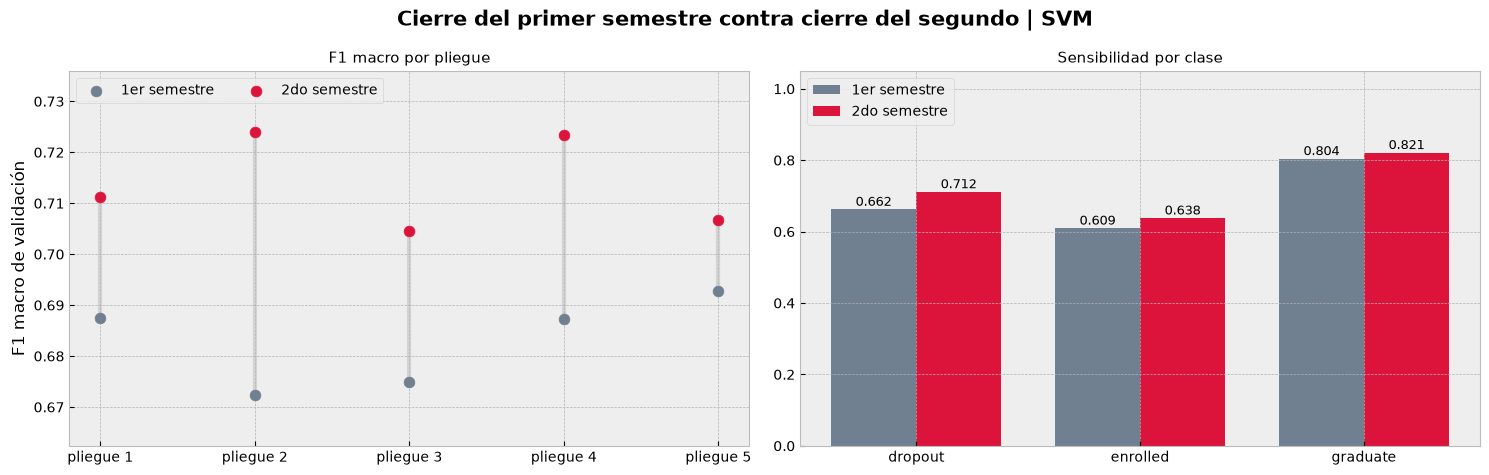

In [35]:
with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    fig.suptitle(f'Cierre del primer semestre contra cierre del segundo | {mejor_clf}', fontweight='bold', fontsize=15)

    # F1 macro de cada pliegue con ambos conjuntos de atributos
    n = np.arange(1, len(f1_1s) + 1)
    for k in range(len(n)):
        axes[0].plot([n[k], n[k]], [f1_1s[k], f1_2s[k]], color='lightgrey', linewidth=3, zorder=1)
    axes[0].scatter(n, f1_1s, s=60, color='slategrey', label='1er semestre', zorder=2)
    axes[0].scatter(n, f1_2s, s=60, color='crimson', label='2do semestre', zorder=2)
    axes[0].set_xticks(n, [f'pliegue {k}' for k in n])
    axes[0].set_ylabel('F1 macro de validación')
    axes[0].set_title('F1 macro por pliegue', fontsize=11)
    axes[0].set_ylim(min(f1_1s.min(), f1_2s.min()) - 0.01, max(f1_1s.max(), f1_2s.max()) + 0.012)
    axes[0].legend(loc='upper left', ncol=2)

    # Sensibilidad por clase
    ancho = 0.38
    x = np.arange(len(orden_clases))
    axes[1].bar(x - ancho / 2, se_1s['sensibilidad'], width=ancho, color='slategrey', label='1er semestre')
    axes[1].bar(x + ancho / 2, se_2s['sensibilidad'], width=ancho, color='crimson', label='2do semestre')
    for k, (a, b) in enumerate(zip(se_1s['sensibilidad'], se_2s['sensibilidad'])):
        axes[1].text(k - ancho / 2, a + 0.01, f'{a:.3f}', ha='center', fontsize=9)
        axes[1].text(k + ancho / 2, b + 0.01, f'{b:.3f}', ha='center', fontsize=9)
    axes[1].set_xticks(x, orden_clases)
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title('Sensibilidad por clase', fontsize=11)
    axes[1].legend(loc='upper left')

    plt.tight_layout()
    plt.show()

Al añadir los seis atributos del segundo semestre, el F1 macro del SVM sube de 0.683 a 0.714 y mejora en los cinco pliegues, por lo que la ganancia es consistente y no producto del azar de la partición. La clase que más se beneficia es la de los desertores, cuya sensibilidad sube de 0.662 a 0.712; la de los inscritos sube de 0.609 a 0.638 y la de los graduados, de 0.804 a 0.821.

La ganancia debe contrastarse con lo que se pierde al esperar un semestre más. Se cuentan los desertores que se detectan solo en cada momento y, como aproximación de cuántos ya se habían desconectado de la carrera al cierre del segundo semestre, los que no inscribieron o no aprobaron ninguna unidad en ese semestre:

In [36]:
es_desertor = (y == 'dropout').to_numpy()
det_1s = es_desertor & (pred_mejor == 'dropout')
det_2s = es_desertor & (pred_2s == 'dropout')
sin_inscritas = (entrena['Curricular units 2nd sem (enrolled)'] == 0).to_numpy()
sin_aprobadas = (entrena['Curricular units 2nd sem (approved)'] == 0).to_numpy()

costo = pd.Series({
    'desertores': es_desertor.sum(),
    'detectados al cierre del 1er semestre': det_1s.sum(),
    'detectados al cierre del 2do semestre': det_2s.sum(),
    'detectados solo al esperar': (det_2s & ~det_1s).sum(),
    'detectados solo al cierre del 1er semestre': (det_1s & ~det_2s).sum(),
    'sin unidades inscritas en el 2do semestre': (es_desertor & sin_inscritas).sum(),
    'sin unidades aprobadas en el 2do semestre': (es_desertor & sin_aprobadas).sum()}, name='estudiantes')
costo.to_frame()

,estudiantes
desertores,1137
detectados al cierre del 1er semestre,753
detectados al cierre del 2do semestre,809
detectados solo al esperar,91
detectados solo al cierre del 1er semestre,35
sin unidades inscritas en el 2do semestre,60
sin unidades aprobadas en el 2do semestre,577


Esperar al cierre del segundo semestre permite detectar a 91 desertores que al cierre del primero pasaban desapercibidos, pero a cambio se dejan de detectar 35 que sí se reconocían, por lo que la ganancia neta es de 56 desertores (de 753 a 809). En cambio, el costo de esperar es considerable: 577 desertores, la mitad de la clase, no aprobaron ninguna unidad en el segundo semestre y 60 ni siquiera inscribieron alguna, señal de que en su mayoría ya se habían desconectado de la carrera. Para ellos, una alerta al cierre del segundo semestre llegaría tarde, mientras que al cierre del primero todavía queda un semestre para intervenir.

Por ello, no conviene esperar: la mejora en la detección de desertores es moderada frente a un semestre completo de retraso, y el modelo del primer semestre ya reconoce a dos de cada tres desertores, con más de 4 de cada 5 alertas correctas. Lo más útil sería aprovechar ambos momentos: predecir al cierre del primer semestre para intervenir a tiempo y actualizar la predicción al cierre del segundo.

## 7. Clasificador final y predicciones

El clasificador final es el mejor de la comparación, con su mejor configuración, entrenado con todo el conjunto de entrenamiento y únicamente con los atributos conocidos al cierre del primer semestre, que son los únicos que trae el conjunto de prueba. Sus predicciones para los 885 estudiantes de prueba se guardan en `predicciones.csv`, con las columnas `id` y `Target`:

In [37]:
clasificador_final = clone(modelos_opt[mejor_clf]).fit(X, y)
predicciones = pd.DataFrame({'id': id_prueba, 'Target': clasificador_final.predict(X_prueba)})
predicciones.to_csv('predicciones.csv', index=False)

# Verificación del formato pedido
assert predicciones.shape == (885, 2) and predicciones['id'].is_unique
assert set(predicciones['Target']) <= set(orden_clases)
print(f"predicciones.csv: {predicciones.shape[0]} estudiantes, columnas {list(predicciones.columns)}")
print(f"Clasificador final: {mejor_clf} | {resumen_busqueda.loc[mejor_clf, 'mejor configuración']}")

distribucion = 100 * pd.DataFrame({'entrenamiento (real)': y.value_counts(normalize=True),
                                   'validación cruzada (predicha)': pd.Series(pred_mejor).value_counts(normalize=True),
                                   'prueba (predicha)': predicciones['Target'].value_counts(normalize=True)}).reindex(orden_clases)
distribucion.round(1)

predicciones.csv: 885 estudiantes, columnas ['id', 'Target']
Clasificador final: SVM | kernel=rbf, class_weight=balanced, C=10.2, gamma=0.00407


,entrenamiento (real),validación cruzada (predicha),prueba (predicha)
dropout,32.1,25.8,24.6
enrolled,17.9,26.0,26.0
graduate,49.9,48.2,49.4


El archivo `predicciones.csv` contiene a los 885 estudiantes de prueba con su clase predicha, en el formato pedido. La distribución de las predicciones de prueba (24.6% desertores, 26.0% inscritos y 49.4% graduados) es muy similar a la de las predicciones de validación cruzada en el entrenamiento (25.8%, 26.0% y 48.2%), lo cual indica que el conjunto de prueba se comporta como el de entrenamiento. En ambos casos, el modelo predice más inscritos de los que hay en realidad (17.9%), efecto de los pesos balanceados, y menos desertores (32.1%), pues parte de ellos se confunden con inscritos. Con base en la validación cruzada, se espera un F1 macro de prueba cercano a 0.68, o ligeramente menor, pues ese valor corresponde a la mejor de 55 configuraciones.

## 8. Discusión y conclusiones

Los cinco clasificadores muestran diferencias claras en este problema. El SVM y la regresión logística obtienen el mejor desempeño, con un F1 macro de 0.683, y no se distinguen entre sí. Ambos se benefician de los pesos balanceados, que mejoran el reconocimiento de la clase minoritaria, y de que la información relevante se concentra en pocos atributos, como las unidades aprobadas y la colegiatura al corriente. El SVM gana por un margen mínimo con un kernel RBF, pero la regresión logística reconoce a más desertores y permite interpretar en qué se apoya cada predicción.

El árbol de decisión queda en un punto intermedio (0.642): sus cortes, de un atributo a la vez, combinan la información con menos eficiencia, pero es de los más rápidos de optimizar y su estructura es fácil de explicar. Naive Bayes (0.621) reconoce bien a los desertores, pero apenas a cuatro de cada diez inscritos, pues la suposición de independencia no se cumple en atributos tan relacionados como las unidades inscritas y aprobadas. kNN (0.579) es el de menor desempeño, ya que con 100 columnas las distancias discriminan poco y la clase mayoritaria domina los vecindarios.

En conclusión, el clasificador final es el SVM con kernel RBF y pesos balanceados, que al cierre del primer semestre reconoce a dos de cada tres desertores, con más de cuatro de cada cinco alertas correctas. Su principal limitación son los desertores que todavía no muestran señales en el primer semestre, ya sea porque abandonan más adelante o porque se cambian de carrera con un buen desempeño. Esperar al segundo semestre mejora el F1 macro en 0.03 y la detección de desertores en cinco puntos porcentuales, pero retrasa la intervención un semestre, cuando la mitad de los desertores ya no aprueba ninguna unidad, por lo que la predicción al cierre del primer semestre es la más útil. Por último, la clase inscrito es la más difícil para todos los clasificadores, al ser una clase intermedia entre graduarse y desertar.

## Referencias

- Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict Students' Dropout and Academic Success [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89.

In [38]:
print("numpy ", np.__version__)
print("pandas ", pd.__version__)
print("matplotlib ", matplotlib.__version__)
print("scikit-learn ", sklearn.__version__)
print("optuna ", optuna.__version__)

numpy  2.5.2
pandas  3.0.5
matplotlib  3.11.0
scikit-learn  1.9.0
optuna  5.0.0


### Declaración de uso de Inteligencia Artificial Generativa

Para esta práctica se utilizó Claude para analizar los niveles poco frecuentes y su agrupación en categorías infrecuentes. Asimismo se utilizó para generar código iterativo para la búsqueda bayesiana de hiperparámetros con Optuna y las gráficas de la meseta de cada búsqueda. Por último, también se empleó para revisar ortografía y estilo, así como para elaborar el archivo README adjunto a la práctica.